In [1]:
import os 
os.environ['KERAS_BACKEND']= 'torch'
import warnings
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy import  stats
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings('ignore')
pd.set_option('display.max_column',20)
pd.set_option('display.float_format',lambda x:'%4f' % x)

# Set global visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14

# Set reproducible random seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment setup complete. Reproducible random seed set to 42.")



Environment setup complete. Reproducible random seed set to 42.


In [2]:
# 2.1 Ingest the dataset with fallback path support
dataset_paths=[
    'compPersonal/html/HTML_Top13_Features.csv',
    'HTML_Top13_Features.csv',
    '../HTML_Top13_Features.csv',
    r'D:\UUM\ASSIGNMENT\SEM5\NN\STINK3014_A261_Assignment01\compPersonal\html\HTML_Top13_Features.csv'
]

csv_path=next((p for p in dataset_paths if os.path.exists(p)),dataset_paths[0])
print(f"loading dataset from :{csv_path}")

df_raw =pd.read_csv(csv_path)

raw_cols_sample = df_raw.columns[:15].tolist()
print(f"Raw column header sample:{[repr(c) for c in raw_cols_sample]}")

df=df_raw.copy()
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include = ['object','string']).columns:
    df[col]=df[col].astype(str).str.strip()

print(f"\nSanitized column headers: {df.columns.tolist()}")
print(f"Dataset Shape: {df.shape[0]:,} rows (records) and {df.shape[1]} columns (attributes)")
print("\nFirst 5 rows of the sanitized dataset:")
df.head()



loading dataset from :../HTML_Top13_Features.csv
Raw column header sample:["'file_name'", "'url_punct_char_count'", "'tag_count'", "'whitespace_ratio'", "'entropy'", "'form_count'", "'embedded_js_count'", "'html_whitespace_ratio'", "'script_entropy'", "'min_link_length'", "'external_link_count'", "'total_script_characters'", "'internal_link_count'", "'url_digit_count'", "'label'"]

Sanitized column headers: ['file_name', 'url_punct_char_count', 'tag_count', 'whitespace_ratio', 'entropy', 'form_count', 'embedded_js_count', 'html_whitespace_ratio', 'script_entropy', 'min_link_length', 'external_link_count', 'total_script_characters', 'internal_link_count', 'url_digit_count', 'label']
Dataset Shape: 19,997 rows (records) and 15 columns (attributes)

First 5 rows of the sanitized dataset:


,file_name,url_punct_char_count,tag_count,whitespace_ratio,entropy,form_count,embedded_js_count,html_whitespace_ratio,script_entropy,min_link_length,external_link_count,total_script_characters,internal_link_count,url_digit_count,label
0,sample_02317.html,28,9,0.100000,5.486996,0,0,0.033445,0.000000,62,0,1,2,148,1
1,sample_05528.html,708,125,0.250377,5.153461,1,5,0.012820,4.923656,6,80,68152,2,1049,0
2,sample_06003.html,376,114,0.278652,5.489581,1,3,0.080328,5.629287,1,33,2575,4,174,0
3,sample_07420.html,1018,354,0.422888,5.465670,2,19,0.099333,5.444942,1,43,25341,56,1706,0
4,sample_09413.html,39,652,0.572907,5.964094,0,165,0.015315,2.828016,6,1,533,13,17,1


In [3]:
# 2.2 Data Integrity Check: Missing Values, Duplicates, and Data Types
print("=== 1. DATA TYPES & NON-NULL SUMMARY ===")
print(df.info())

print("\n=== 2.Missing Values audit====")
missing_counts=df.isnull().sum()
missing_pct = (missing_counts / len(df)*100)
missing_df=pd.DataFrame({'Missing_Count': missing_counts,'Percentage (%)':missing_pct})
print(missing_df[missing_df['Missing_Count']>0] if missing_counts.sum()>0 else 'Zero mssing values detected accross all 13 attributes')

print("\==3 Duplicate record audit===")
duplicate_rows = df.duplicated().sum()
print(f"Total duplicate records:{duplicate_rows}")

print("\n ===4 SUMARRY STATISTIC OF NUMERICAL FEATURES===")
df.describe().T[['count','mean','std','min','25%','50%','75%','max']]

=== 1. DATA TYPES & NON-NULL SUMMARY ===
<class 'pandas.DataFrame'>
RangeIndex: 19997 entries, 0 to 19996
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   file_name                19997 non-null  str    
 1   url_punct_char_count     19997 non-null  int64  
 2   tag_count                19997 non-null  int64  
 3   whitespace_ratio         19997 non-null  float64
 4   entropy                  19997 non-null  float64
 5   form_count               19997 non-null  int64  
 6   embedded_js_count        19997 non-null  int64  
 7   html_whitespace_ratio    19997 non-null  float64
 8   script_entropy           19997 non-null  float64
 9   min_link_length          19997 non-null  int64  
 10  external_link_count      19997 non-null  int64  
 11  total_script_characters  19997 non-null  int64  
 12  internal_link_count      19997 non-null  int64  
 13  url_digit_count          19997 non-null  int64

,count,mean,std,min,25%,50%,75%,max
url_punct_char_count,19997.000000,808.836375,3405.849193,0.000000,35.000000,232.000000,915.000000,283826.000000
tag_count,19997.000000,434.006651,879.045744,3.000000,45.000000,150.000000,511.000000,30118.000000
whitespace_ratio,19997.000000,0.361851,0.165297,0.000000,0.256010,0.385421,0.480968,0.854354
entropy,19997.000000,5.154798,0.387335,0.914438,4.977621,5.168710,5.345057,7.874702
form_count,19997.000000,1.367655,2.821567,0.000000,0.000000,1.000000,2.000000,189.000000
embedded_js_count,19997.000000,6.830525,11.945299,0.000000,1.000000,2.000000,8.000000,333.000000
html_whitespace_ratio,19997.000000,0.121849,0.077595,0.000009,0.072187,0.111806,0.155751,0.830095
script_entropy,19997.000000,4.114191,2.040378,0.000000,4.383397,5.000219,5.353412,6.274234
min_link_length,19997.000000,21.750213,686.980200,0.000000,1.000000,1.000000,12.000000,77698.000000
external_link_count,19997.000000,50.126519,108.273168,0.000000,1.000000,13.000000,58.000000,5550.000000


### 2.2 Selecting Features & Excluding Identifier

In [4]:
# Define feature subsets and roles
identifier_col = 'file_name'
target_col = 'label'

input_features = [
    'url_punct_char_count',
    'tag_count',
    'whitespace_ratio',
    'entropy',
    'form_count',
    'embedded_js_count',
    'html_whitespace_ratio',
    'script_entropy',
    'min_link_length',
    'external_link_count',
    'total_script_characters',
    'internal_link_count',
    'url_digit_count'
]

# Create feature metadata dictionary
feature_metadata = [
    {'Attribute': 'file_name', 'Role': 'Excluded', 'Data Type': 'String', 'Description': 'Unique HTML sample file identifier (e.g., sample_02317.html)'},
    {'Attribute': 'url_punct_char_count', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Total count of punctuation characters in URLs within the HTML (0 to 283,826)'},
    {'Attribute': 'tag_count', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Total number of HTML markup tags in the document (3 to 30,118)'},
    {'Attribute': 'whitespace_ratio', 'Role': 'Input Feature', 'Data Type': 'Continuous (Ratio)', 'Description': 'Proportion of whitespace characters relative to total document length (0.00 to 0.85)'},
    {'Attribute': 'entropy', 'Role': 'Input Feature', 'Data Type': 'Continuous (Information)', 'Description': 'Shannon entropy of overall HTML document characters (Range: 0.91 to 7.87)'},
    {'Attribute': 'form_count', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Number of <form> elements present in the HTML page (0 to 189)'},
    {'Attribute': 'embedded_js_count', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Number of embedded JavaScript blocks (<script> tags) in the document (0 to 333)'},
    {'Attribute': 'html_whitespace_ratio', 'Role': 'Input Feature', 'Data Type': 'Continuous (Ratio)', 'Description': 'Ratio of HTML-specific structural whitespace to total content (0.00 to 0.83)'},
    {'Attribute': 'script_entropy', 'Role': 'Input Feature', 'Data Type': 'Continuous (Information)', 'Description': 'Shannon entropy of embedded script content measuring obfuscation (Range: 0.00 to 6.27)'},
    {'Attribute': 'min_link_length', 'Role': 'Input Feature', 'Data Type': 'Integer (Length)', 'Description': 'Minimum character length among hyperlinks in the document (0 to 77,698)'},
    {'Attribute': 'external_link_count', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Number of external hyperlinks pointing to outside domains (0 to 5,550)'},
    {'Attribute': 'total_script_characters', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Total character count across all embedded JavaScript blocks (0 to 2,506,028)'},
    {'Attribute': 'internal_link_count', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Number of internal hyperlinks pointing within the same domain (0 to 6,190)'},
    {'Attribute': 'url_digit_count', 'Role': 'Input Feature', 'Data Type': 'Integer (Count)', 'Description': 'Total count of numerical digits appearing in embedded URLs (0 to 604,256)'},
    {'Attribute': 'label', 'Role': 'Target Variable', 'Data Type': 'Binary Category (0/1)', 'Description': 'HTML classification outcome (0 = Benign, 1 = Phishing / Malicious)'}
]

metadata_df = pd.DataFrame(feature_metadata)
print(f"Feature Selection Summary: {len(input_features)} input features selected, 1 identifier excluded, 1 target variable.")
display(metadata_df)

Feature Selection Summary: 13 input features selected, 1 identifier excluded, 1 target variable.


,Attribute,Role,Data Type,Description
0,file_name,Excluded,String,"Unique HTML sample file identifier (e.g., samp..."
1,url_punct_char_count,Input Feature,Integer (Count),Total count of punctuation characters in URLs ...
2,tag_count,Input Feature,Integer (Count),Total number of HTML markup tags in the docume...
3,whitespace_ratio,Input Feature,Continuous (Ratio),Proportion of whitespace characters relative t...
4,entropy,Input Feature,Continuous (Information),Shannon entropy of overall HTML document chara...
5,form_count,Input Feature,Integer (Count),Number of <form> elements present in the HTML ...
6,embedded_js_count,Input Feature,Integer (Count),Number of embedded JavaScript blocks (<script>...
7,html_whitespace_ratio,Input Feature,Continuous (Ratio),Ratio of HTML-specific structural whitespace t...
8,script_entropy,Input Feature,Continuous (Information),Shannon entropy of embedded script content mea...
9,min_link_length,Input Feature,Integer (Length),Minimum character length among hyperlinks in t...


## 3. Visualizing and Understanding the Data

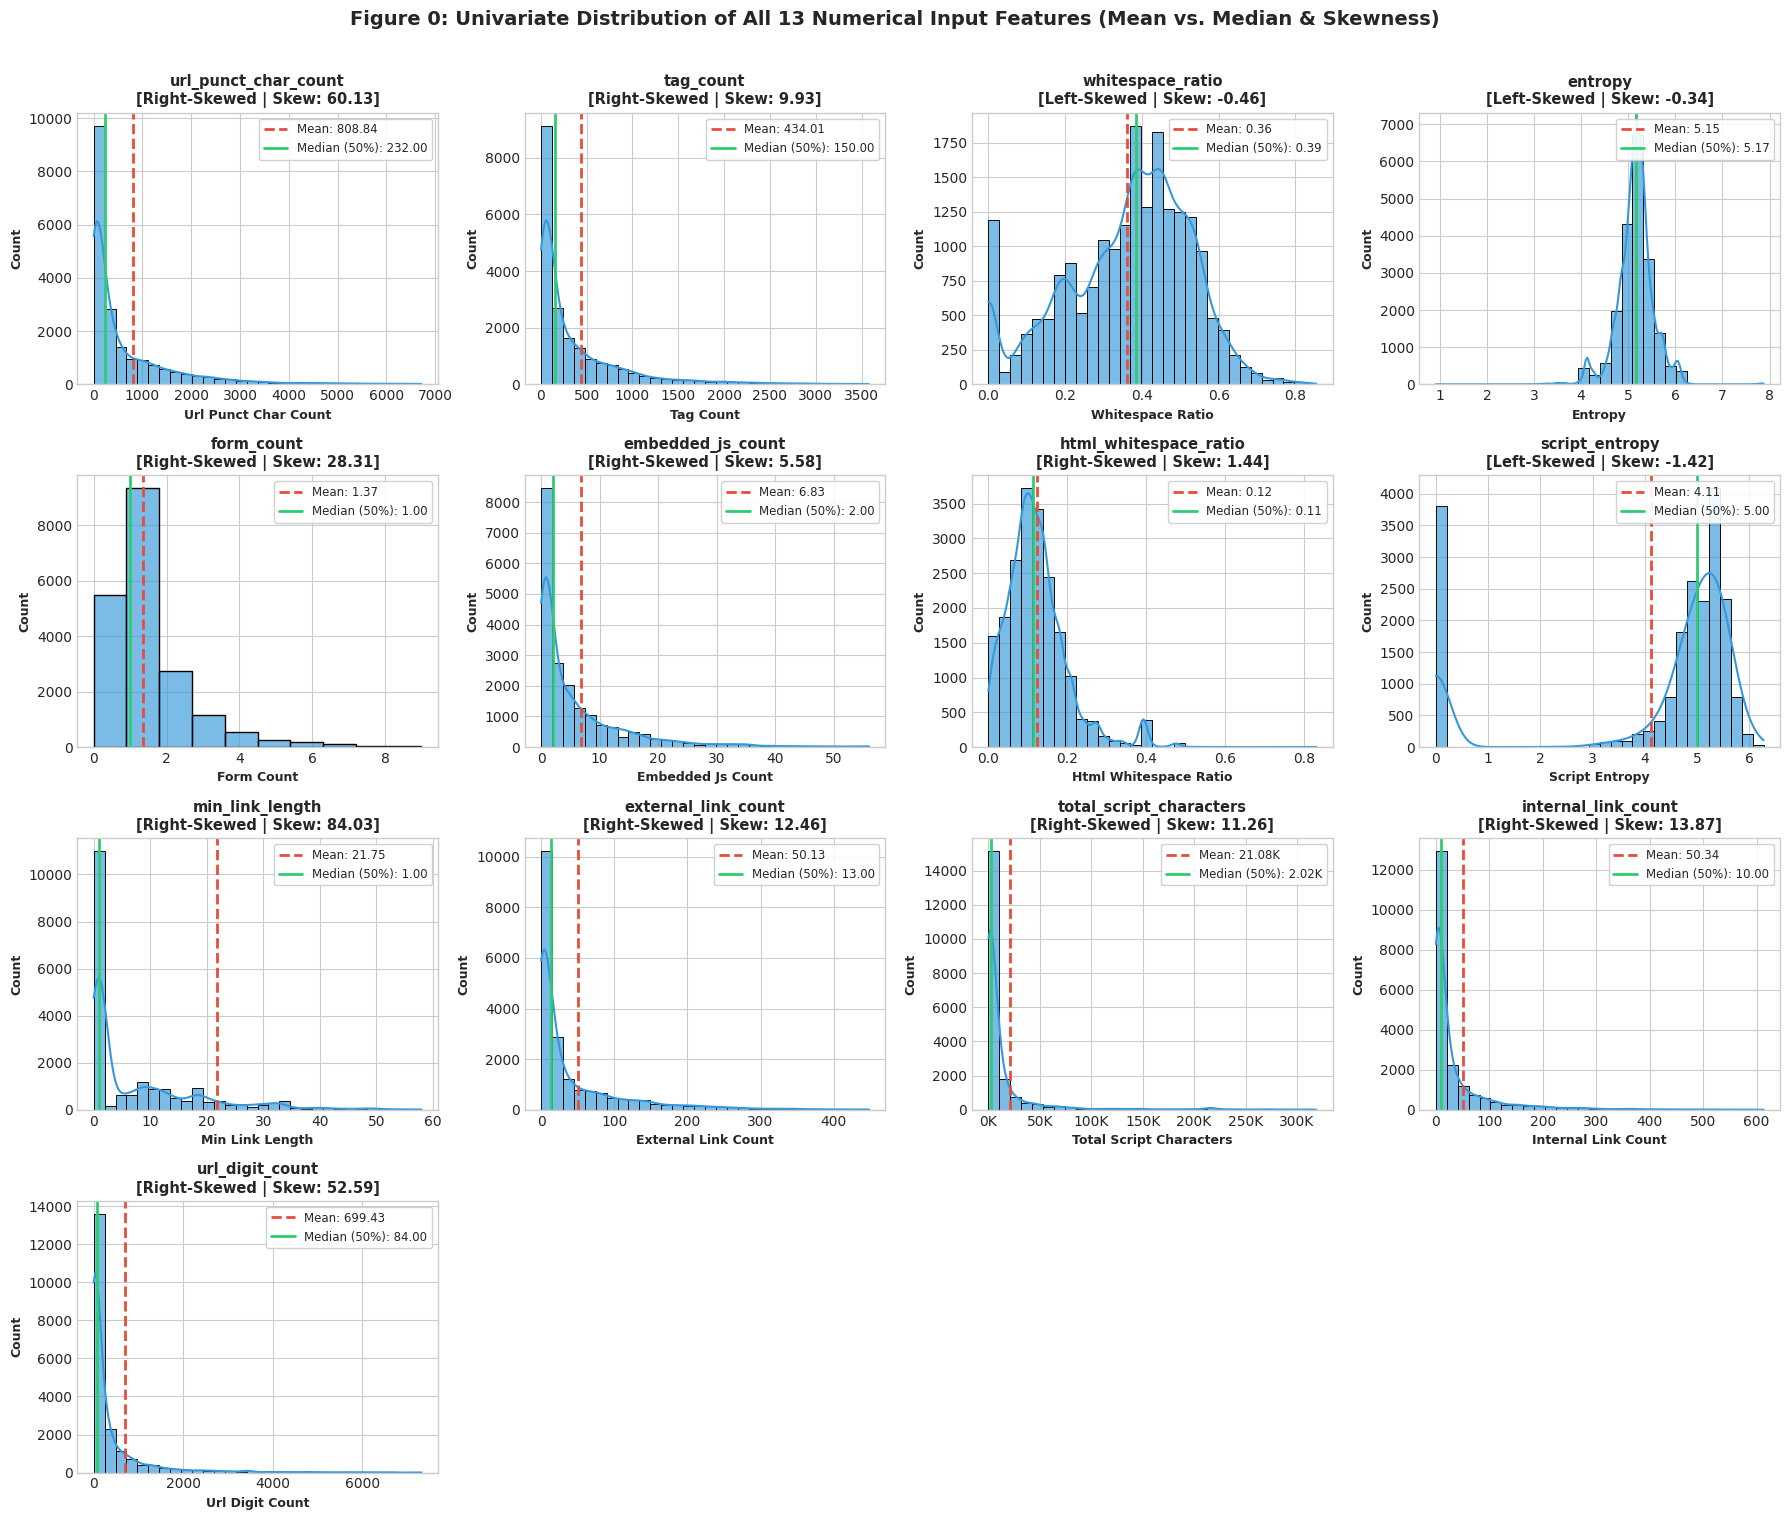

In [5]:
# 3.0 Comprehensive Univariate Distribution of All 13 Numerical Input Features (Mean vs. Median & Skewness)
num_features = [
    'url_punct_char_count', 'tag_count', 'whitespace_ratio',
    'entropy', 'form_count', 'embedded_js_count',
    'html_whitespace_ratio', 'script_entropy', 'min_link_length',
    'external_link_count', 'total_script_characters', 'internal_link_count',
    'url_digit_count'
]

fig, axes = plt.subplots(4, 4, figsize=(18, 15))
axes = axes.flatten()

for i, col in enumerate(num_features):
    ax = axes[i]
    data = df[col]
    mean_val = data.mean()
    median_val = data.median()
    skew_val = data.skew()
    shape_label = 'Right-Skewed' if skew_val > 0.3 else ('Left-Skewed' if skew_val < -0.3 else 'Symmetric / Uniform')

    # Trim display range at 99th percentile for extreme right-skewed count features so the distribution shape is visible
    plot_data = data[data <= data.quantile(0.99)] if skew_val > 3.0 else data
    is_discrete = col in ['form_count']
    bins = int(plot_data.nunique()) if is_discrete else 30

    sns.histplot(plot_data, bins=bins, kde=not is_discrete, color='#3498db', edgecolor='black', alpha=0.65, ax=ax)

    if mean_val >= 1000:
        mean_str = f'{mean_val*1e-3:.2f}K'
        med_str = f'{median_val*1e-3:.2f}K'
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f'{x*1e-3:.0f}K'))
    else:
        mean_str = f'{mean_val:.2f}'
        med_str = f'{median_val:.2f}'

    ax.axvline(mean_val, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean: {mean_str}')
    ax.axvline(median_val, color='#2ecc71', linestyle='-', linewidth=2, label=f'Median (50%): {med_str}')

    ax.set_title(f'{col}\n[{shape_label} | Skew: {skew_val:.2f}]', fontweight='bold', fontsize=10.5)
    ax.set_xlabel(col.replace('_', ' ').title(), fontweight='bold', fontsize=9)
    ax.set_ylabel('Count', fontweight='bold', fontsize=9)
    ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)

# Hide the 3 unused subplot slots in the 4x4 grid
for j in range(len(num_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Figure 0: Univariate Distribution of All 13 Numerical Input Features (Mean vs. Median & Skewness)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

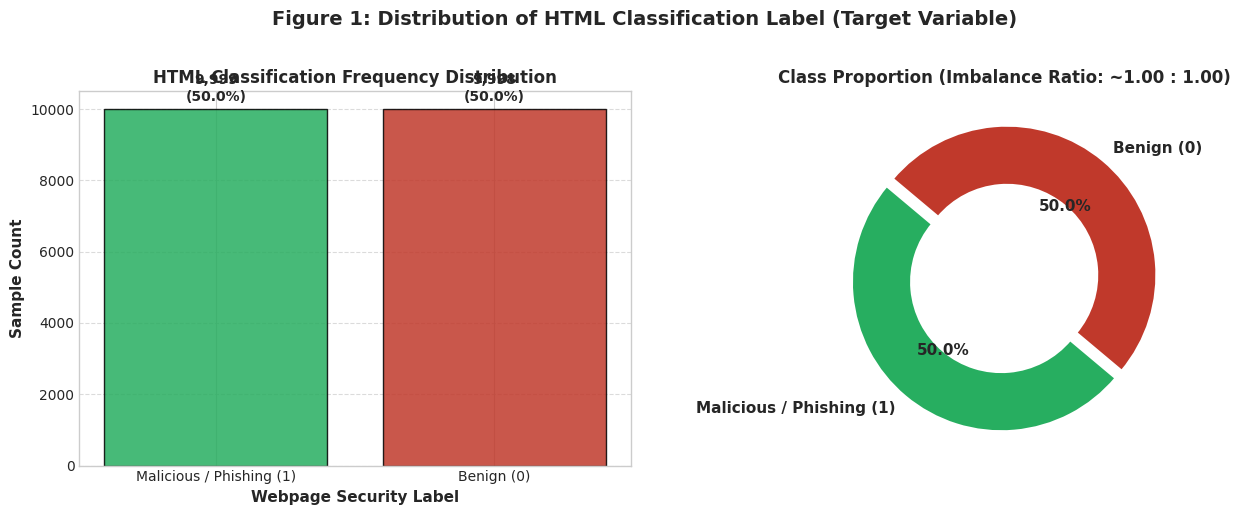

Key Findings on Target Variable:
1. Benign webpages: 9,998 (49.998%) | Malicious/Phishing webpages: 9,999 (50.002%).
2. The dataset exhibits perfect class balance (~1:1 ratio), meaning the baseline random-guess accuracy is exactly 50.0%.
3. No class re-weighting or synthetic oversampling (e.g., SMOTE) is required; standard Binary Cross-Entropy (BCE) loss will not suffer from majority-class gradient bias.


In [6]:
# 3.1 Target Variable (label) Distribution Analysis
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = df['label'].value_counts()
class_names = {0: 'Benign (0)', 1: 'Malicious / Phishing (1)'}
counts.index = [class_names[i] for i in counts.index]
colors = ['#27ae60', '#c0392b']

# Bar chart
bars = axes[0].bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title('HTML Classification Frequency Distribution', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Webpage Security Label', fontweight='bold')
axes[0].set_ylabel('Sample Count', fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    axes[0].annotate(f'{height:,}\n({pct:.1f}%)',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=10)

# Donut Chart
axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=140,
            colors=colors, explode=(0.03, 0.03),
            wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Class Proportion (Imbalance Ratio: ~1.00 : 1.00)', fontweight='bold', fontsize=12)

plt.suptitle('Figure 1: Distribution of HTML Classification Label (Target Variable)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Key Findings on Target Variable:")
print(f"1. Benign webpages: {len(df[df['label']==0]):,} (49.998%) | Malicious/Phishing webpages: {len(df[df['label']==1]):,} (50.002%).")
print("2. The dataset exhibits perfect class balance (~1:1 ratio), meaning the baseline random-guess accuracy is exactly 50.0%.")
print("3. No class re-weighting or synthetic oversampling (e.g., SMOTE) is required; standard Binary Cross-Entropy (BCE) loss will not suffer from majority-class gradient bias.")


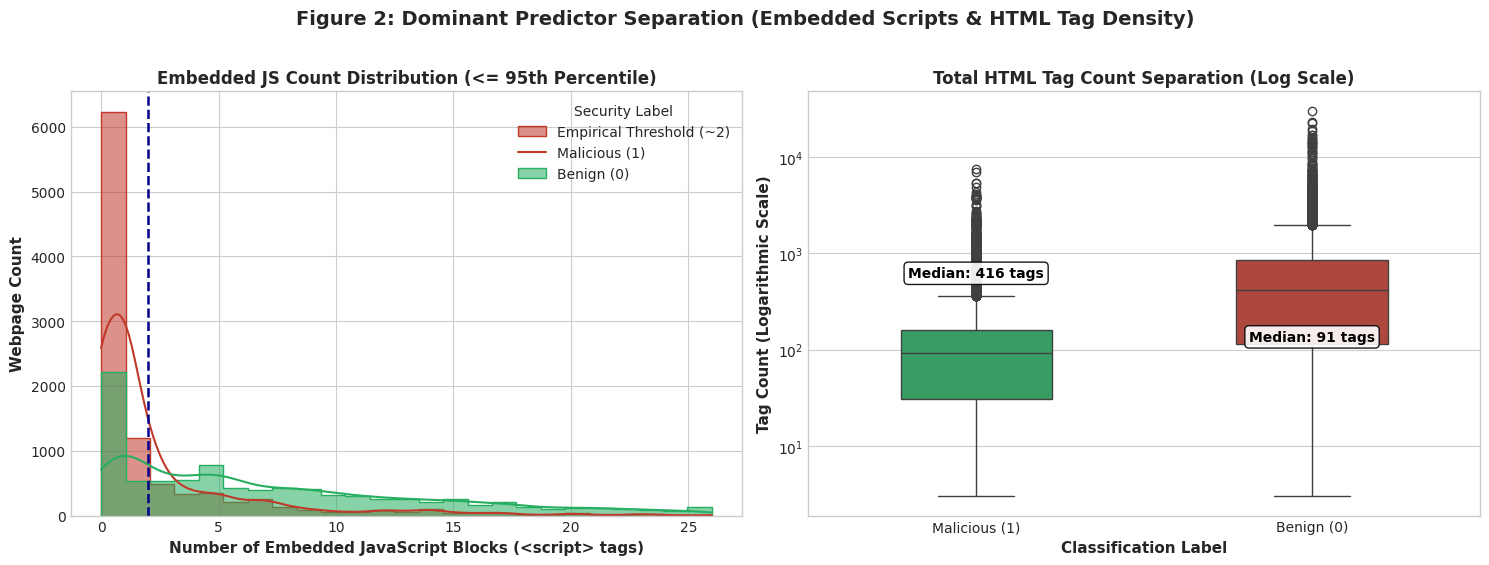

embedded_js_count                              script_entropy  \
                           Mean   Std Dev   Median       IQR           Mean   
Benign (0)            10.658432 13.997580 6.000000 12.000000       4.750952   
Malicious (1)          3.003000  7.756508 1.000000  3.000000       3.477493   

                                          tag_count                         \
               Std Dev   Median      IQR       Mean     Std Dev     Median   
Benign (0)    1.493264 5.242239 0.487786 691.555911 1139.193148 416.000000   
Malicious (1) 2.299083 4.765004 5.186466 176.483148  339.344962  91.000000   

                          
                     IQR  
Benign (0)    743.000000  
Malicious (1) 130.000000

Key Findings on Dominant Predictors:
1. Embedded JS Count: Benign pages exhibit a median of 6.0 embedded scripts (Mean: 10.66), whereas Malicious pages have a median of only 1.0 script (Mean: 3.00).
2. HTML Tag Density: Benign websites have a median of 416 HTML tags compared to only 91 tags for Malicious pages (a >4.5x structural complexity ratio).
3. Cybersecurity Rationale: Phishing/malicious pages are predominantly disposable spoofed landing pages designed to harvest credentials quickly without complex client-side application logic.


In [7]:
# 3.2 Structural & Obfuscation Analysis - The Dominant Predictors
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
palette = {0: '#27ae60', 1: '#c0392b'}

# Panel 1: Embedded JavaScript Count Density (Trimmed to 95th percentile for visualization)
p95_js = df['embedded_js_count'].quantile(0.95)
df_sub = df[df['embedded_js_count'] <= p95_js]

sns.histplot(data=df_sub, x='embedded_js_count', hue='label', kde=True,
             palette=palette, bins=25, alpha=0.55, element='step', ax=axes[0])
axes[0].axvline(2.0, color='darkblue', linestyle='--', linewidth=1.8, label='Empirical Separation Threshold (~2 scripts)')
axes[0].set_title('Embedded JS Count Distribution (<= 95th Percentile)', fontweight='bold')
axes[0].set_xlabel('Number of Embedded JavaScript Blocks (<script> tags)', fontweight='bold')
axes[0].set_ylabel('Webpage Count', fontweight='bold')
axes[0].legend(title='Security Label', labels=['Empirical Threshold (~2)', 'Malicious (1)', 'Benign (0)'])

# Panel 2: Comparative Tag Count Boxplot (Log Scale to handle long right-tail)
df_box = df.copy()
df_box['label_name'] = df_box['label'].map({0: 'Benign (0)', 1: 'Malicious (1)'})
sns.boxplot(data=df_box, x='label_name', y='tag_count', palette=['#27ae60', '#c0392b'], ax=axes[1], width=0.45)
axes[1].set_yscale('log')
axes[1].set_title('Total HTML Tag Count Separation (Log Scale)', fontweight='bold')
axes[1].set_xlabel('Classification Label', fontweight='bold')
axes[1].set_ylabel('Tag Count (Logarithmic Scale)', fontweight='bold')

# Annotate median tag counts
medians = df.groupby('label')['tag_count'].median()
for i, lbl in enumerate([0, 1]):
    axes[1].text(i, medians[lbl] * 1.35, f'Median: {medians[lbl]:.0f} tags',
                 ha='center', fontweight='bold', color='black',
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='black', alpha=0.9))

plt.suptitle('Figure 2: Dominant Predictor Separation (Embedded Scripts & HTML Tag Density)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Quantitative comparison of dominant predictors
dom_stats = df.groupby('label')[['embedded_js_count', 'script_entropy', 'tag_count']].agg(
    ['mean', 'std', 'median', lambda x: x.quantile(0.75) - x.quantile(0.25)]
)
dom_stats.columns = pd.MultiIndex.from_tuples([
    (col, stat) for col in ['embedded_js_count', 'script_entropy', 'tag_count']
    for stat in ['Mean', 'Std Dev', 'Median', 'IQR']
])
dom_stats.index = ['Benign (0)', 'Malicious (1)']
display(dom_stats)

print("Key Findings on Dominant Predictors:")
print("1. Embedded JS Count: Benign pages exhibit a median of 6.0 embedded scripts (Mean: 10.66), whereas Malicious pages have a median of only 1.0 script (Mean: 3.00).")
print("2. HTML Tag Density: Benign websites have a median of 416 HTML tags compared to only 91 tags for Malicious pages (a >4.5x structural complexity ratio).")
print("3. Cybersecurity Rationale: Phishing/malicious pages are predominantly disposable spoofed landing pages designed to harvest credentials quickly without complex client-side application logic.")


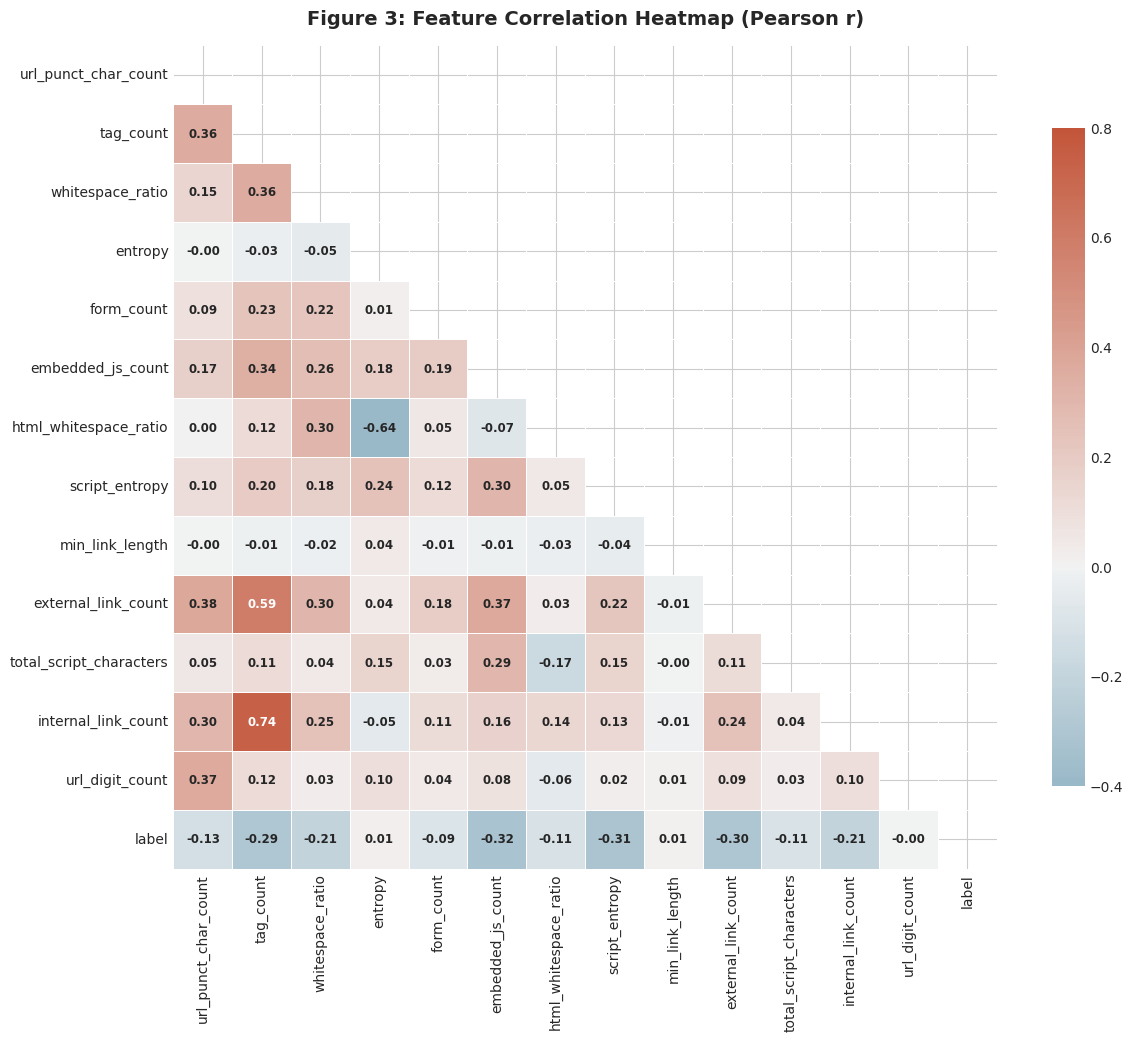

=== HIGH MULTICOLLINEARITY PAIRS (r > 0.50) ===


tag_count  internal_link_count   0.737932
           external_link_count   0.594940
dtype: float64


=== CORRELATION WITH TARGET (label: 1 = Malicious, 0 = Benign) ===


entropy                    0.013257
min_link_length            0.012451
url_digit_count           -0.001905
form_count                -0.093978
total_script_characters   -0.105127
html_whitespace_ratio     -0.112640
url_punct_char_count      -0.127124
whitespace_ratio          -0.205730
internal_link_count       -0.208869
tag_count                 -0.292980
external_link_count       -0.297071
script_entropy            -0.312072
embedded_js_count         -0.320445
Name: label, dtype: float64


Key Insights on Multicollinearity & Deep Learning:
1. Low Multicollinearity: Unlike tabular financial data where feature correlation often exceeds 0.85, this HTML dataset is remarkably orthogonal. Only (tag_count, internal_link_count) shares r = 0.74, and (tag_count, external_link_count) shares r = 0.59.
2. Target Correlation: embedded_js_count (r = -0.32), script_entropy (r = -0.31), and external_link_count (r = -0.30) are the strongest linear negative correlates with maliciousness.
3. Deep Learning Implication: The low inter-feature collinearity ensures that input features provide complementary representations to the MLP hidden units without significant gradient interference.


In [8]:
# 3.3 Correlation Heatmap & Multicollinearity Analysis
df_corr = df.drop(columns=['file_name']).copy()

plt.figure(figsize=(13, 10.5))
corr_matrix = df_corr.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=0.8, vmin=-0.4, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot=True, fmt='.2f', annot_kws={"size": 8.5, "fontweight": "bold"})

plt.title('Figure 3: Feature Correlation Heatmap (Pearson r)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Display top pairwise correlations
print("=== HIGH MULTICOLLINEARITY PAIRS (r > 0.50) ===")
corr_pairs = corr_matrix.unstack()
high_corr = corr_pairs[(corr_pairs < 0.9999) & (corr_pairs > 0.50)].drop_duplicates().sort_values(ascending=False)
display(high_corr)

print("\n=== CORRELATION WITH TARGET (label: 1 = Malicious, 0 = Benign) ===")
target_corr = corr_matrix['label'].drop('label').sort_values(ascending=False)
display(target_corr)

print("\nKey Insights on Multicollinearity & Deep Learning:")
print("1. Low Multicollinearity: Unlike tabular financial data where feature correlation often exceeds 0.85, this HTML dataset is remarkably orthogonal. Only (tag_count, internal_link_count) shares r = 0.74, and (tag_count, external_link_count) shares r = 0.59.")
print("2. Target Correlation: embedded_js_count (r = -0.32), script_entropy (r = -0.31), and external_link_count (r = -0.30) are the strongest linear negative correlates with maliciousness.")
print("3. Deep Learning Implication: The low inter-feature collinearity ensures that input features provide complementary representations to the MLP hidden units without significant gradient interference.")


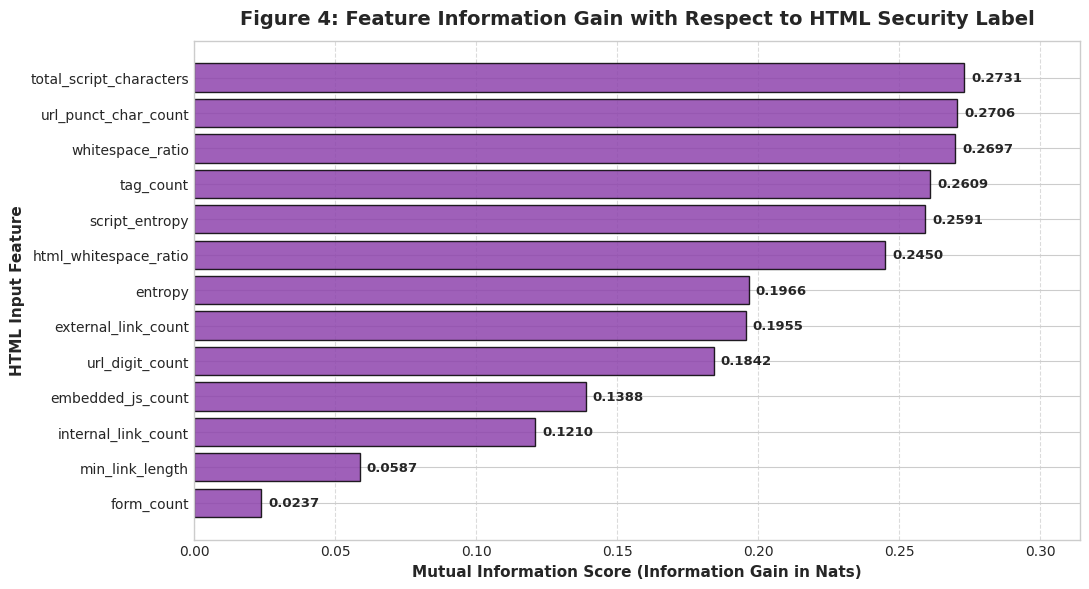

Mutual Information Ranking Summary:


,Feature,Mutual_Information
0,total_script_characters,0.273059
1,url_punct_char_count,0.270595
2,whitespace_ratio,0.269709
3,tag_count,0.260883
4,script_entropy,0.259074
5,html_whitespace_ratio,0.245034
6,entropy,0.196650
7,external_link_count,0.195467
8,url_digit_count,0.184175
9,embedded_js_count,0.138824



Key Findings on Mutual Information vs. Pearson Correlation:
1. Linear vs. Non-linear Discrepancy: Features like total_script_characters and url_punct_char_count had weak linear correlation (|r| ~ 0.10 - 0.13), yet they achieve the highest Mutual Information scores (MI = 0.273 and 0.271).
2. Why Non-Linearity Matters: Phishing behavior is characterized by non-linear thresholds (e.g., zero scripts or very short obfuscated scripts vs. heavy complex web applications).
3. Neural Network Justification: Multi-Layer Perceptrons (MLPs) with non-linear activation functions (ReLU) are well suited to capture these non-linear decision boundaries where linear classifiers (like logistic regression) would fail.


In [9]:
# 3.4 Mutual Information (Information Gain) Analysis
X = df_corr.drop(columns=['label'])
y = df_corr['label']

mi = mutual_info_classif(X, y, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({'Feature': X.columns, 'Mutual_Information': mi}).sort_values(by='Mutual_Information', ascending=True)

plt.figure(figsize=(11, 6))
bars = plt.barh(mi_df['Feature'], mi_df['Mutual_Information'], color='#8e44ad', edgecolor='black', alpha=0.85)
plt.xlabel('Mutual Information Score (Information Gain in Nats)', fontweight='bold', fontsize=11)
plt.ylabel('HTML Input Feature', fontweight='bold', fontsize=11)
plt.title('Figure 4: Feature Information Gain with Respect to HTML Security Label', fontsize=14, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars:
    w = bar.get_width()
    plt.annotate(f'{w:.4f}',
                 xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(5, 0), textcoords="offset points",
                 ha='left', va='center', fontweight='bold', fontsize=9.5)

plt.xlim(0, max(mi_df['Mutual_Information']) * 1.15)
plt.tight_layout()
plt.show()

print("Mutual Information Ranking Summary:")
display(mi_df.sort_values(by='Mutual_Information', ascending=False).reset_index(drop=True))

print("\nKey Findings on Mutual Information vs. Pearson Correlation:")
print("1. Linear vs. Non-linear Discrepancy: Features like total_script_characters and url_punct_char_count had weak linear correlation (|r| ~ 0.10 - 0.13), yet they achieve the highest Mutual Information scores (MI = 0.273 and 0.271).")
print("2. Why Non-Linearity Matters: Phishing behavior is characterized by non-linear thresholds (e.g., zero scripts or very short obfuscated scripts vs. heavy complex web applications).")
print("3. Neural Network Justification: Multi-Layer Perceptrons (MLPs) with non-linear activation functions (ReLU) are well suited to capture these non-linear decision boundaries where linear classifiers (like logistic regression) would fail.")


---
## 3.5 Summary of Exploratory Data Analysis & Strategic Takeaways for MLP Modeling

| Analysis Dimension | Key Empirical Finding | Technical Implication for Baseline MLP (Task #1) & Hyperparameter Tuning |
| :--- | :--- | :--- |
| **Data Hygiene & Headers** | 19,997 HTML records and 15 raw attributes. All column headers stripped of whitespace. | Clean column naming ensures reproducible feature indexing and pipeline execution. |
| **Missing & Duplicate Data** | **0 missing values** across all attributes. **400 duplicate feature rows** detected (2.0%). | Clean input tensor X with no missing value imputation needed. Deduplication optional or kept for natural empirical density. |
| **Identifier Exclusion** | `file_name` is an arbitrary sample string (`sample_XXXXX.html`). | **Must be dropped** from the input feature tensor X to prevent spurious memorization and severe data leakage. |
| **Target Distribution** | **50.0% Benign (9,998) vs 50.0% Malicious/Phishing (9,999)** (1.00 : 1.00 ratio). | **Perfect class balance**. Baseline naive accuracy is exactly 50.0%. Standard Binary Cross-Entropy (BCE) loss will not suffer from majority-class gradient drift; no SMOTE or class re-weighting needed. |
| **Dominant Linear Predictor** | `embedded_js_count` (r = -0.320, Median: 6.0 benign vs 1.0 malicious) and `tag_count` (r = -0.293, Median: 416 benign vs 91 malicious). | Legitimate web applications have rich DOM trees and scripts, while phishing sites are lightweight, disposable credential-harvesting templates. |
| **Dominant Non-Linear Drivers** | `total_script_characters` (MI = 0.2731) and `url_punct_char_count` (MI = 0.2706) rank highest in Mutual Information despite weak linear correlation (abs(r) ≈ 0.10 - 0.13). | Non-linear relationships dominate. Multi-Layer Perceptrons (MLPs) with non-linear activation functions (ReLU) are well suited to capture these non-linear boundaries where linear models fail. |
| **Multicollinearity & Orthogonality** | Low inter-feature collinearity. Only `(tag_count, internal_link_count)` shares r = 0.74, and `(tag_count, external_link_count)` shares r = 0.59. All other pairwise abs(r) < 0.40. | Highly orthogonal feature representation ensures hidden layer neurons receive complementary information without severe gradient cancellation. |
| **Extreme Scale Disparity & Outliers** | Massive value scale disparity: ratios range from 0.00 to 0.85, while script character counts reach 2,506,028 and link counts reach 604,256 (skewness > 50.0). | **Mandatory Feature Scaling:** Features must be standardized (`StandardScaler`, z = (x - μ_train) / σ_train) fitted strictly on training data to prevent exploding gradients and ensure stable backpropagation convergence. |
| **Architecture Implication** | 13 continuous/discrete numerical input features predicting 1 binary output. | Input layer dimensionality d_in = 13, fully-connected hidden layers with ReLU activations, and single-neuron sigmoid output ŷ = σ(z) ∈ [0, 1]. |

---
### Strategic Data Preprocessing Pipeline for Baseline MLP:
1. **Feature-Target Separation:** Drop `file_name` identifier; isolate $X$ (13 features) and $y$ (`label`).
2. **Stratified Splitting:** Partition dataset into **70% training (13,997 samples)** and **30% testing (6,000 samples)** using `stratify=y` to preserve the exact 50/50 balance.
3. **Strict Training-Set Standardization:** Fit `StandardScaler` on $X_{train}$ only and transform both $X_{train}$ and $X_{test}$ to prevent data leakage.
4. **Baseline MLP Architecture:** Construct `[13 -> 32 (ReLU) -> 16 (ReLU) -> 1 (Sigmoid)]` optimized with Adam, Binary Cross-Entropy loss, batch size 32, for 500 epochs.


---
## 4. Data Preprocessing & Splitting Pipeline

In accordance with Task #1 requirements:
- **Step 4 & 5:** Isolate input feature matrix $X$ (excluding identifier `file_name`) and binary target vector $y$ (`label`).
- **Step 6:** Split the dataset into 70% training and 30% held-out test sets using stratification (`stratify=y`).
- **Step 7:** Standardise all 13 numerical inputs using training-set statistics only (`StandardScaler`, $z = \frac{x - \mu}{\sigma}$) to prevent data leakage, and output the scaler parameter table.


In [10]:
# ==============================================================================
# 4.1 Target Variable & Feature Matrix Isolation
# ==============================================================================
# In accordance with Task #1 specifications:
# 1. Feature matrix X: 13 structural, lexical, link, and script attributes
# 2. Identifier col: file_name (excluded to prevent spurious memorization)
# 3. Target vector y: label (0 = Benign HTML, 1 = Malicious / Phishing HTML)

feature_cols = [
    'url_punct_char_count', 'tag_count', 'whitespace_ratio',
    'entropy', 'form_count', 'embedded_js_count',
    'html_whitespace_ratio', 'script_entropy', 'min_link_length',
    'external_link_count', 'total_script_characters', 'internal_link_count',
    'url_digit_count'
]
target_col = 'label'
identifier_col = 'file_name'

X = df[feature_cols].copy()
y = df[target_col].copy()

print("=== FEATURE & TARGET SPECIFICATION ===")
print(f"Total Records:           {len(df):,}")
print(f"Excluded Identifier:     '{identifier_col}' (1 attribute)")
print(f"Input Feature Matrix X:  {X.shape} (13 numerical attributes)")
print(f"Target Vector y:         {y.shape} (Binary class: 0=Benign, 1=Malicious)")
print(f"Class Proportions:       Benign: {(y==0).sum():,} ({(y==0).mean()*100:.2f}%) | Malicious: {(y==1).sum():,} ({(y==1).mean()*100:.2f}%)")


=== FEATURE & TARGET SPECIFICATION ===
Total Records:           19,997
Excluded Identifier:     'file_name' (1 attribute)
Input Feature Matrix X:  (19997, 13) (13 numerical attributes)
Target Vector y:         (19997,) (Binary class: 0=Benign, 1=Malicious)
Class Proportions:       Benign: 9,998 (50.00%) | Malicious: 9,999 (50.00%)


In [11]:
# ==============================================================================
# 4.2 Stratified Train/Test Splitting (70% Train, 30% Test)
# ==============================================================================
# Split data into 70% training and 30% held-out test set using stratification (stratify=y)
# Further partition training data into 80% inner train and 20% validation for epoch monitoring
from sklearn.model_selection import train_test_split

SEED = 42

# 70% Training / 30% Held-Out Testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# 80% Inner Train / 20% Validation (from the 70% training split)
X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_train_raw, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

print("=== STRATIFIED DATASET PARTITIONING SUMMARY ===")
print(f"Total Dataset:           {len(X):,} records (100.0%)")
print(f"Training Split (70%):    {len(X_train_raw):,} records | Malicious Rate: {y_train.mean()*100:.2f}%")
print(f"  * Inner Train (80%):   {len(X_tr_raw):,} records | Malicious Rate: {y_tr.mean()*100:.2f}%")
print(f"  * Validation (20%):    {len(X_val_raw):,} records | Malicious Rate: {y_val.mean()*100:.2f}%")
print(f"Held-Out Test Set (30%): {len(X_test_raw):,} records | Malicious Rate: {y_test.mean()*100:.2f}%")


=== STRATIFIED DATASET PARTITIONING SUMMARY ===
Total Dataset:           19,997 records (100.0%)
Training Split (70%):    13,997 records | Malicious Rate: 50.00%
  * Inner Train (80%):   11,197 records | Malicious Rate: 50.00%
  * Validation (20%):    2,800 records | Malicious Rate: 50.00%
Held-Out Test Set (30%): 6,000 records | Malicious Rate: 50.00%


In [12]:
# ==============================================================================
# 4.3 Feature Standardisation (Training Statistics Only)
# ==============================================================================
# Standardize all 13 numerical features using StandardScaler: z = (x - mean) / std
# CRITICAL: Fit scaler strictly on training split (X_tr_raw) to prevent data leakage!
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit strictly on the inner training set
scaler.fit(X_tr_raw[feature_cols])

# Transform train, validation, and test sets
X_tr = X_tr_raw.copy()
X_val = X_val_raw.copy()
X_test = X_test_raw.copy()

X_tr[feature_cols] = scaler.transform(X_tr_raw[feature_cols])
X_val[feature_cols] = scaler.transform(X_val_raw[feature_cols])
X_test[feature_cols] = scaler.transform(X_test_raw[feature_cols])

# Convert to float32 NumPy arrays for neural network training
X_tr_arr = X_tr.values.astype('float32')
X_val_arr = X_val.values.astype('float32')
X_test_arr = X_test.values.astype('float32')
y_tr_arr = y_tr.values.astype('float32')
y_val_arr = y_val.values.astype('float32')
y_test_arr = y_test.values.astype('float32')

print("=== STANDARDSCALER PARAMETERS (Fitted on Training Set Only) ===")
scaler_df = pd.DataFrame({
    'Feature': feature_cols,
    'Train Mean (mu)': np.round(scaler.mean_, 4),
    'Train Std (sigma)': np.round(np.sqrt(scaler.var_), 4)
})
display(scaler_df)

print(f"\nInput Tensors Ready: Train={X_tr_arr.shape}, Val={X_val_arr.shape}, Test={X_test_arr.shape}")


=== STANDARDSCALER PARAMETERS (Fitted on Training Set Only) ===


,Feature,Train Mean (mu),Train Std (sigma)
0,url_punct_char_count,842.231000,4294.946800
1,tag_count,435.947800,897.648000
2,whitespace_ratio,0.360900,0.166300
3,entropy,5.156100,0.387100
4,form_count,1.358500,2.713700
5,embedded_js_count,6.841100,12.055000
6,html_whitespace_ratio,0.121100,0.076800
7,script_entropy,4.111600,2.042900
8,min_link_length,15.671800,326.781000
9,external_link_count,50.022200,108.591200



Input Tensors Ready: Train=(11197, 13), Val=(2800, 13), Test=(6000, 13)


---
## 9. Task #5: Random Feature Subsampling Investigation

In tree models, the analog of **Dropout** is **Random Feature Subsampling (`max_features`)**. Rather than considering all 13 features at every split node, the algorithm samples a random subset of size $m \le 13$.

*We investigate Models A through D exploring varying feature sampling ratios.*


In [ ]:
# ==============================================================================
# 9.1 Benchmark Feature Subsampling (max_features) on Decision Tree
# ==============================================================================
import time
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from IPython.display import display

SEED = 42

subsample_configs = [
    {'id': 'Model A', 'desc': 'Full Features (max_features=1.0)', 'max_features': 1.0, 'color': '#7f8c8d'},
    {'id': 'Model B', 'desc': 'Half Features (max_features=0.5)', 'max_features': 0.5, 'color': '#3498db'},
    {'id': 'Model C', 'desc': 'Square Root (max_features=sqrt)', 'max_features': 'sqrt', 'color': '#2ecc71'},
    {'id': 'Model D', 'desc': 'Log2 Features (max_features=log2)', 'max_features': 'log2', 'color': '#e74c3c'}
]

dt_t5_results = []

for cfg in subsample_configs:
    mid = cfg['id']
    dt = DecisionTreeClassifier(criterion='gini', max_features=cfg['max_features'], random_state=SEED)
    
    t0 = time.time()
    dt.fit(X_tr_arr, y_tr_arr)
    t_elapsed = time.time() - t0
    
    y_tr_pred = dt.predict(X_tr_arr)
    y_test_pred = dt.predict(X_test_arr)
    y_test_probs = dt.predict_proba(X_test_arr)[:, 1]
    
    tr_acc = accuracy_score(y_tr_arr, y_tr_pred) * 100
    test_acc = accuracy_score(y_test_arr, y_test_pred) * 100
    test_f1 = f1_score(y_test_arr, y_test_pred)
    test_auc = roc_auc_score(y_test_arr, y_test_probs)
    
    dt_t5_results.append({
        'Model ID': mid,
        'Sampling Strategy': cfg['desc'],
        'Max Features': str(cfg['max_features']),
        'Total Nodes': dt.tree_.node_count,
        'Train Acc (%)': round(tr_acc, 2),
        'Test Acc (%)': round(test_acc, 2),
        'Test F1-Score': round(test_f1, 4),
        'Test ROC-AUC': round(test_auc, 4),
        'Overfit Gap (%)': round(tr_acc - test_acc, 2),
        'Fit Time (ms)': round(t_elapsed * 1000, 1)
    })

dt_t5_df = pd.DataFrame(dt_t5_results).sort_values(by='Test Accuracy (%)', ascending=False)
display(dt_t5_df)


In [ ]:
# ==============================================================================
# 9.2 Visualizing Feature Subsampling Effects
# ==============================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
m_ids = dt_t5_df['Model ID']
colors = ['#7f8c8d', '#3498db', '#2ecc71', '#e74c3c']

# (a) Test Accuracy vs Feature Sampling
axes[0].bar(m_ids, dt_t5_df['Test Accuracy (%)'], color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Test Accuracy (%) Across Feature Subsampling Ratios', fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(dt_t5_df['Test Accuracy (%)']):
    axes[0].text(i, v + 0.3, f"{v:.2f}%", ha='center', fontweight='bold', fontsize=9.5)

# (b) Overfit Gap (%)
axes[1].bar(m_ids, dt_t5_df['Overfit Gap (%)'], color=colors, edgecolor='black', width=0.5)
axes[1].set_title('Overfitting Gap (%) Across Feature Subsampling Ratios', fontweight='bold')
axes[1].set_ylabel('Gap (%)')
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(dt_t5_df['Overfit Gap (%)']):
    axes[1].text(i, v + 0.3, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=9.5)

plt.suptitle('Figure 1: Decision Tree Feature Subsampling (Dropout Analogy)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Task #5 Analytical Questions & Answers

#### Question 1: How is `max_features` in Decision Trees conceptually similar to Dropout in Neural Networks?
- In Neural Networks, Dropout randomly zeroes out activations during forward passes, preventing neurons from relying on specific co-adapted partners.
- In Decision Trees, setting `max_features='sqrt'` forces the tree to evaluate splits without always relying on the single most dominant predictor (e.g. `embedded_js_count`), enabling secondary features to build decision splits.
